# Demo pipeline — Ảnh UAV đa phổ plot_B03

Notebook **trình diễn** kết quả của cả nhóm trên cùng một ảnh:

| Lớp | Nguồn | Người phụ trách |
| :--- | :--- | :--- |
| RGB, CIR | `data/outputs/cog_multispectral.tif` (COG 5 band, EPSG:32630, 0,0413 m) | Nam Anh |
| NDVI, NDRE, LULC | `ndvi.tif`, `ndre.tif`, `lulc_class.tif`, `lulc_summary.json` | Quang Anh |
| Tán cọ dầu | `detections.geojson`, `palm_stats.json` | Hinh |

Quy tắc (hợp đồng dữ liệu, mục D):
1. **Chỉ đọc** `data/outputs/*` — notebook không ghi file nào.
2. Đọc ảnh ở **độ phân giải giảm** (`out_shape`) để cả notebook chạy **< 30 giây**.
3. **Không chạy YOLO** — chỉ vẽ lại `detections.geojson`.

Muốn tạo lại output: `python scripts/03_spectral_ndvi_analysis.py` (nhánh phổ), `python scripts/02_yolo_drone_detection.py` (nhánh YOLO).

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import rasterio
from rasterio.enums import Resampling
from pyproj import Transformer
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle

T0 = time.perf_counter()

# Chạy được dù mở notebook từ thư mục gốc repo hay từ notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data" / "outputs").exists() else Path.cwd().parent
OUT = ROOT / "data" / "outputs"
FILES = {
    "cog": OUT / "cog_multispectral.tif",
    "ndvi": OUT / "ndvi.tif",
    "ndre": OUT / "ndre.tif",
    "lulc": OUT / "lulc_class.tif",
    "summary": OUT / "lulc_summary.json",
    "stats": OUT / "spectral_stats.json",
    "detections": OUT / "detections.geojson",
    "palm": OUT / "palm_stats.json",
}
missing = [k for k, p in FILES.items() if not p.exists()]
assert not missing, f"Thiếu output: {missing} — chạy các script trong scripts/ trước."

SCALE = 4  # đọc 1/4 độ phân giải: 4419×4434 px → ~1105×1109 px (pixel ~16,5 cm)
plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 11, "axes.titlelocation": "left"})
print("Đủ", len(FILES), "file output trong", OUT.relative_to(ROOT).as_posix())

Đủ 8 file output trong data/outputs


## 1. Đọc COG ở độ phân giải giảm

`out_shape` + `Resampling.average` để rasterio lấy thẳng từ **overview** của COG (đã dựng sẵn ở mức 2, 4, 8, 16) — nhanh hơn nhiều so với đọc full rồi thu nhỏ.

In [2]:
with rasterio.open(FILES["cog"]) as src:
    H, W = src.height // SCALE, src.width // SCALE
    bands = src.read(out_shape=(5, H, W), resampling=Resampling.average).astype(np.float32)
    mask = src.read_masks(1, out_shape=(H, W), resampling=Resampling.nearest) > 0
    crs = src.crs
    tf_small = src.transform * src.transform.scale(src.width / W, src.height / H)
    desc = src.descriptions
    full = (src.width, src.height, src.res[0])

print(f"COG gốc  : {full[0]}×{full[1]} px, pixel {full[2]} m, CRS {crs}")
print(f"Đọc vào  : {W}×{H} px, band = {desc}")
print(f"Pixel hợp lệ (mask): {mask.mean():.1%}")

def stretch(rgb, m=mask, p=(2, 98)):
    """Kéo giãn tương phản 2–98% cho từng band, nền ngoài mask = trắng."""
    out = np.zeros(rgb.shape[1:] + (3,), np.float32)
    for i in range(3):
        lo, hi = np.percentile(rgb[i][m], p)
        out[..., i] = np.clip((rgb[i] - lo) / (hi - lo), 0, 1)
    out[~m] = 1.0
    return out

EXTENT = (tf_small.c, tf_small.c + W * tf_small.a, tf_small.f + H * tf_small.e, tf_small.f)  # mét UTM

COG gốc  : 4419×4434 px, pixel 0.0413 m, CRS EPSG:32630
Đọc vào  : 1104×1108 px, band = ('Blue', 'Green', 'Red', 'RedEdge', 'NIR')
Pixel hợp lệ (mask): 75.2%


## 2. RGB và CIR (màu giả hồng ngoại)

- **RGB** = band 3-2-1 (Red, Green, Blue): màu tự nhiên.
- **CIR** = band 5-3-2 (NIR, Red, Green): NIR hiển thị bằng màu **đỏ** → thực vật khỏe (phản xạ NIR mạnh) hiện **đỏ tươi**, đất trống hiện xám/xanh nhạt.

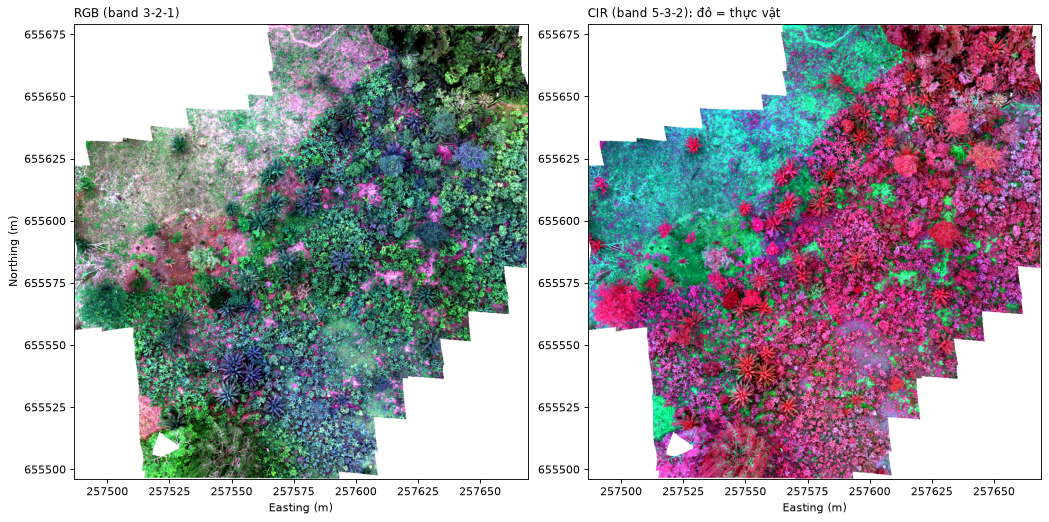

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), layout="constrained")
axes[0].imshow(stretch(bands[[2, 1, 0]]), extent=EXTENT)
axes[0].set_title("RGB (band 3-2-1)")
axes[1].imshow(stretch(bands[[4, 2, 1]]), extent=EXTENT)
axes[1].set_title("CIR (band 5-3-2): đỏ = thực vật")
for ax in axes:
    ax.set_xlabel("Easting (m)"); ax.ticklabel_format(useOffset=False, style="plain")
axes[0].set_ylabel("Northing (m)")
plt.show()

## 3. NDVI và NDRE

$$\text{NDVI} = \frac{NIR - Red}{NIR + Red} \qquad \text{NDRE} = \frac{NIR - RedEdge}{NIR + RedEdge}$$

Đọc từ `ndvi.tif` / `ndre.tif` do script 03 xuất (Float32, NaN = không có dữ liệu). Dữ liệu là **DN chưa hiệu chuẩn phản xạ** nên giá trị mang ý nghĩa **tương đối** (đất trống ra NDVI âm).

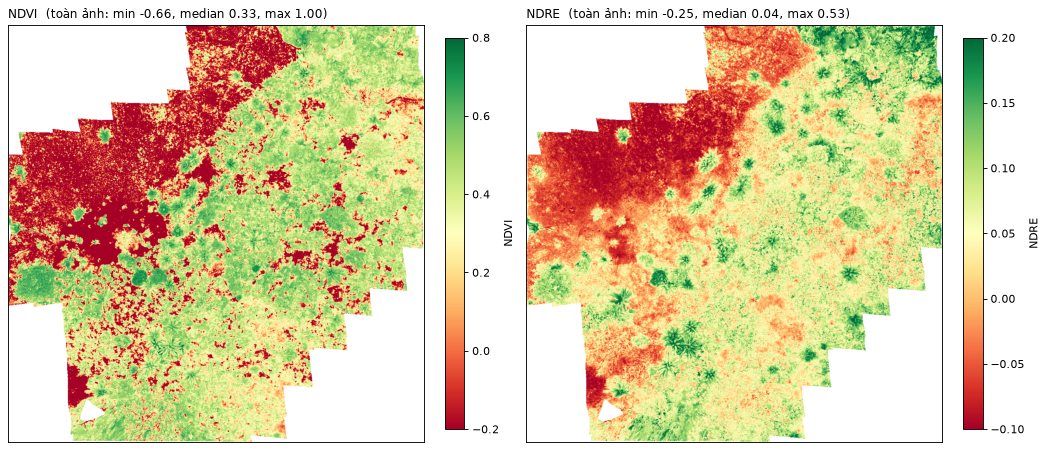

In [4]:
def read_index(path):
    with rasterio.open(path) as ds:
        a = ds.read(1, out_shape=(H, W), resampling=Resampling.average, masked=True)
    return a.filled(np.nan)

ndvi, ndre = read_index(FILES["ndvi"]), read_index(FILES["ndre"])
stats = json.loads(FILES["stats"].read_text(encoding="utf-8"))

fig, axes = plt.subplots(1, 2, figsize=(13, 6.2), layout="constrained")
for ax, arr, name, lim in ((axes[0], ndvi, "NDVI", (-0.2, 0.8)), (axes[1], ndre, "NDRE", (-0.1, 0.2))):
    im = ax.imshow(arr, cmap="RdYlGn", vmin=lim[0], vmax=lim[1], extent=EXTENT)
    s = stats[name.lower()]
    ax.set_title(f"{name}  (toàn ảnh: min {s['min']:.2f}, median {s['median']:.2f}, max {s['max']:.2f})")
    ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, shrink=0.8, label=name)
plt.show()

## 4. Phân lớp LULC và diện tích

4 lớp theo ngưỡng NDVI chọn bằng **Otsu phân tầng** (chi tiết: `docs/spectral_notes.md`, kiểm tra: `docs/spectral_qa.md`). Màu lấy từ bảng màu nhúng trong `lulc_class.tif`.

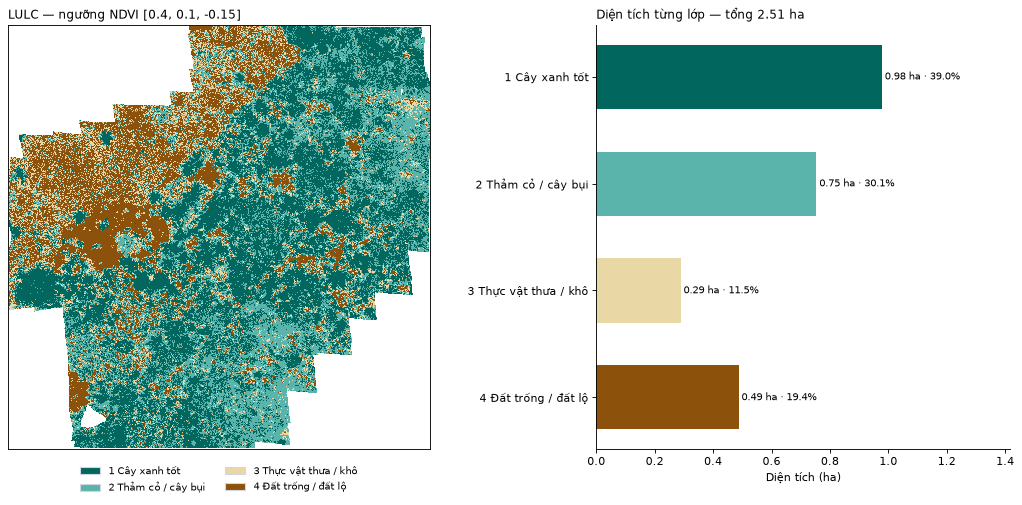

Lớp                              Khoảng NDVI          m²       ha       %
1 Cây xanh tốt                [+0.40, +1.00]    9,777.32   0.9777   39.00
2 Thảm cỏ / cây bụi           [+0.10, +0.40]    7,533.79   0.7534   30.05
3 Thực vật thưa / khô         [-0.15, +0.10]    2,886.23   0.2886   11.51
4 Đất trống / đất lộ          [-1.00, -0.15]    4,870.75   0.4871   19.43
Tổng                                           25,068.08   2.5068


In [5]:
summary = json.loads(FILES["summary"].read_text(encoding="utf-8"))
with rasterio.open(FILES["lulc"]) as ds:
    lulc = ds.read(1, out_shape=(H, W), resampling=Resampling.nearest)  # nearest: không trộn mã lớp
    cmap_raw = ds.colormap(1)

colors = {c["id"]: tuple(v / 255 for v in cmap_raw[c["id"]][:3]) for c in summary["classes"]}
cmap = ListedColormap([(1, 1, 1)] + [colors[i] for i in (1, 2, 3, 4)])
legend = [Patch(facecolor=colors[c["id"]], edgecolor="#d0d7de", label=f"{c['id']} {c['name']}") for c in summary["classes"]]

fig, (ax, axb) = plt.subplots(1, 2, figsize=(13, 6.2), width_ratios=[1.15, 1], layout="constrained")
ax.imshow(lulc, cmap=cmap, vmin=0, vmax=4, interpolation="nearest", extent=EXTENT)
ax.set_title(f"LULC — ngưỡng NDVI {summary['ndvi_thresholds']}")
ax.set_xticks([]); ax.set_yticks([])
ax.legend(handles=legend, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2, frameon=False, fontsize=9)

names = [f"{c['id']} {c['name']}" for c in summary["classes"]][::-1]
ha = [c["area_ha"] for c in summary["classes"]][::-1]
bars = axb.barh(names, ha, color=[colors[c["id"]] for c in summary["classes"]][::-1], height=0.6)
for b, c in zip(bars, summary["classes"][::-1]):
    axb.text(b.get_width() + 0.01, b.get_y() + b.get_height() / 2, f"{c['area_ha']:.2f} ha · {c['percent']:.1f}%",
             va="center", fontsize=9)
axb.set_xlim(0, max(ha) * 1.45)
axb.set_xlabel("Diện tích (ha)")
axb.set_title(f"Diện tích từng lớp — tổng {summary['total_valid_area_ha']} ha")
axb.spines[["top", "right"]].set_visible(False)
plt.show()

print(f"{'Lớp':<26}{'Khoảng NDVI':>18}{'m²':>12}{'ha':>9}{'%':>8}")
for c in summary["classes"]:
    rng = f"[{c['ndvi_range'][0]:+.2f}, {c['ndvi_range'][1]:+.2f}]"
    print(f"{c['id']} {c['name']:<24}{rng:>18}{c['area_m2']:>12,.2f}{c['area_ha']:>9.4f}{c['percent']:>8.2f}")
print(f"{'Tổng':<44}{summary['total_valid_area_m2']:>12,.2f}{summary['total_valid_area_m2']/1e4:>9.4f}")

## 5. Tán cọ dầu phát hiện bằng YOLO (nhánh Hinh)

Đọc `detections.geojson` (EPSG:4326, lon/lat) → đổi sang UTM 32630 bằng `pyproj` để chồng lên ảnh. Notebook **không chạy YOLO**.

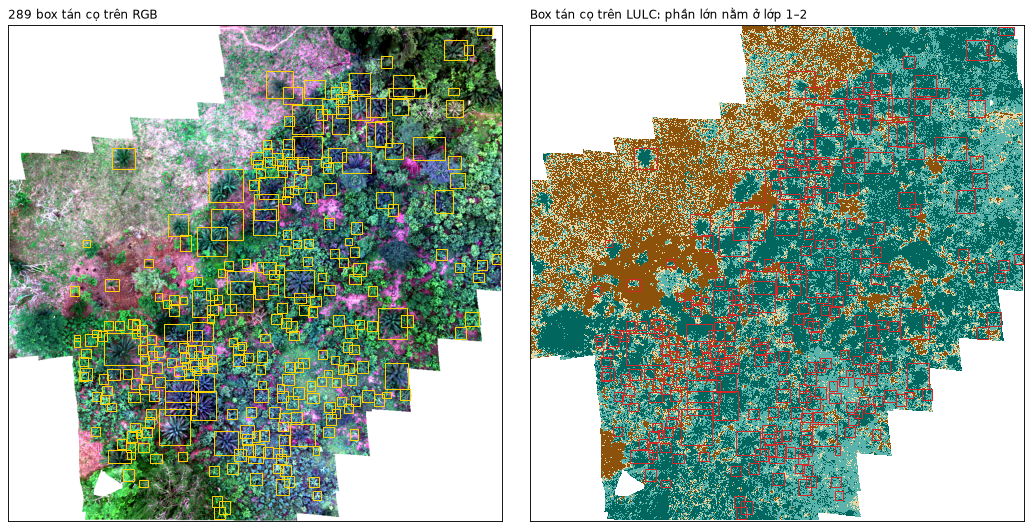

Số cây cọ: 289  |  Mật độ: 115.33 cây/ha
Đường kính tán (m): min 2.07, median 3.78, mean 4.49, max 12.44


In [6]:
gj = json.loads(FILES["detections"].read_text(encoding="utf-8"))
palm_stats = json.loads(FILES["palm"].read_text(encoding="utf-8"))
to_utm = Transformer.from_crs("EPSG:4326", crs, always_xy=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), layout="constrained")
axes[0].imshow(stretch(bands[[2, 1, 0]]), extent=EXTENT)
axes[1].imshow(lulc, cmap=cmap, vmin=0, vmax=4, interpolation="nearest", extent=EXTENT)
for f in gj["features"]:
    xs, ys = zip(*(to_utm.transform(x, y) for x, y in f["geometry"]["coordinates"][0]))
    for ax, col in ((axes[0], "#ffd400"), (axes[1], "#d62728")):
        ax.add_patch(Rectangle((min(xs), min(ys)), max(xs) - min(xs), max(ys) - min(ys),
                               fill=False, edgecolor=col, linewidth=0.9))
axes[0].set_title(f"{len(gj['features'])} box tán cọ trên RGB")
axes[1].set_title("Box tán cọ trên LULC: phần lớn nằm ở lớp 1–2")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

d = palm_stats["crown_diameter_m"]
print(f"Số cây cọ: {palm_stats['total_palms']}  |  Mật độ: {palm_stats['density_per_ha']} cây/ha")
print(f"Đường kính tán (m): min {d['min']}, median {d['median']}, mean {d['mean']}, max {d['max']}")

## 6. Xuất hình cho báo cáo

Vẽ lại từng lớp thành **hình đơn** (có thanh tỉ lệ) và lưu vào `docs/figures/demo_*` (ảnh JPEG, riêng LULC là PNG) để chèn báo cáo. Đây là thư mục tài liệu, **không phải** `data/outputs/` — notebook vẫn không ghi đè output nào. Đặt `EXPORT_FIGURES = False` nếu chỉ muốn xem.

In [7]:
EXPORT_FIGURES = True
FIG_DIR = ROOT / "docs" / "figures"

def scalebar(ax, length_m=20):
    """Thanh tỉ lệ ở góc dưới phải (trục đang ở mét UTM)."""
    x1, x0 = EXTENT[1] - 6, EXTENT[1] - 6 - length_m
    y = EXTENT[2] + 6
    ax.plot([x0, x1], [y, y], color="black", linewidth=4, solid_capstyle="butt")
    ax.plot([x0, x1], [y, y], color="white", linewidth=2, solid_capstyle="butt")
    ax.text((x0 + x1) / 2, y + 2, f"{length_m} m", ha="center", va="bottom", fontsize=10,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))

def export(name, draw, legend_handles=None, cbar=None, ext="jpg"):
    """Ảnh dạng chụp → JPEG (nhẹ); bản đồ lớp ít màu → PNG (giữ màu sắc nét)."""
    fig, ax = plt.subplots(figsize=(6.5, 6.8), layout="constrained")
    im = draw(ax)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlim(EXTENT[0], EXTENT[1]); ax.set_ylim(EXTENT[2], EXTENT[3])
    scalebar(ax)
    if cbar:
        fig.colorbar(im, ax=ax, shrink=0.75, label=cbar, location="bottom", pad=0.02)
    if legend_handles:
        fig.legend(handles=legend_handles, loc="outside lower center", ncol=2, frameon=False, fontsize=9)
    path = FIG_DIR / f"demo_{name}.{ext}"
    fig.savefig(path, dpi=150, **({"pil_kwargs": {"quality": 88}} if ext == "jpg" else {}))
    plt.close(fig)
    return path

def draw_palms(ax, color):
    for f in gj["features"]:
        xs, ys = zip(*(to_utm.transform(x, y) for x, y in f["geometry"]["coordinates"][0]))
        ax.add_patch(Rectangle((min(xs), min(ys)), max(xs) - min(xs), max(ys) - min(ys),
                               fill=False, edgecolor=color, linewidth=0.8))

if EXPORT_FIGURES:
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    rgb, cir = stretch(bands[[2, 1, 0]]), stretch(bands[[4, 2, 1]])
    saved = [
        export("rgb", lambda ax: ax.imshow(rgb, extent=EXTENT)),
        export("cir", lambda ax: ax.imshow(cir, extent=EXTENT)),
        export("ndvi", lambda ax: ax.imshow(ndvi, cmap="RdYlGn", vmin=-0.2, vmax=0.8, extent=EXTENT), cbar="NDVI"),
        export("ndre", lambda ax: ax.imshow(ndre, cmap="RdYlGn", vmin=-0.1, vmax=0.2, extent=EXTENT), cbar="NDRE"),
        export("lulc", lambda ax: ax.imshow(lulc, cmap=cmap, vmin=0, vmax=4, interpolation="nearest", extent=EXTENT),
               legend_handles=legend, ext="png"),
        export("palm_overlay", lambda ax: (ax.imshow(rgb, extent=EXTENT), draw_palms(ax, "#ffd400"))[0]),
    ]
    for p in saved:
        print("Đã lưu", p.relative_to(ROOT).as_posix(), f"({p.stat().st_size // 1024} KB)")

Đã lưu docs/figures/demo_rgb.jpg (394 KB)
Đã lưu docs/figures/demo_cir.jpg (381 KB)
Đã lưu docs/figures/demo_ndvi.jpg (348 KB)
Đã lưu docs/figures/demo_ndre.jpg (304 KB)
Đã lưu docs/figures/demo_lulc.png (255 KB)
Đã lưu docs/figures/demo_palm_overlay.jpg (418 KB)


## 7. Tóm tắt

In [8]:
print(f"Diện tích hợp lệ : {summary['total_valid_area_ha']} ha")
for c in summary["classes"]:
    print(f"  {c['name']:<22}: {c['area_ha']:.2f} ha ({c['percent']:.1f}%)")
print(f"Cây cọ (YOLO)    : {palm_stats['total_palms']} cây, {palm_stats['density_per_ha']} cây/ha")
print(f"Thời gian chạy notebook: {time.perf_counter() - T0:.1f} s")

Diện tích hợp lệ : 2.51 ha
  Cây xanh tốt          : 0.98 ha (39.0%)
  Thảm cỏ / cây bụi     : 0.75 ha (30.1%)
  Thực vật thưa / khô   : 0.29 ha (11.5%)
  Đất trống / đất lộ    : 0.49 ha (19.4%)
Cây cọ (YOLO)    : 289 cây, 115.33 cây/ha
Thời gian chạy notebook: 6.3 s
